In [224]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [154]:
heat = "C:\\AI Equipment Failure Prediction\\data\\17_열처리.csv"  
heat_work = "C:\\AI Equipment Failure Prediction\\data\\17_열처리_공정.csv"  
heatt = "C:\\AI Equipment Failure Prediction\\data\\18_열처리.csv"  

In [161]:
# Windows에 설치된 맑은 고딕을 사용합니다.
plt.rcParams["font.family"] = "Malgun Gothic"

# 일부 글꼴에서 음수 기호가 깨지는 문제를 피합니다.
plt.rcParams["axes.unicode_minus"] = False

In [6]:
df = pd.read_csv(heat)
df.head()

,측정시각,배치,온도,OP값,CP값,상태
0,09:00,로트A,861.9,42.9,0.451,정상
1,09:10,로트A,858.4,97.6,0.446,정상
2,09:20,로트A,858.7,89.8,0.450,정상
3,09:30,로트A,860.7,57.3,0.450,정상
4,09:40,로트A,859.1,87.8,0.452,정상


In [12]:
상태_counts = df["상태"].value_counts()
상태_counts

상태
정상    42
승온     2
Name: count, dtype: int64

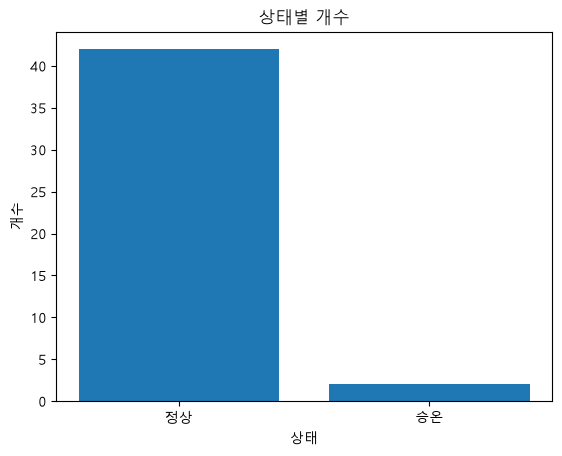

In [13]:
plt.bar(상태_counts.index, 상태_counts.values)
plt.xlabel("상태")
plt.ylabel("개수")
plt.title("상태별 개수")
plt.show()

In [7]:
df.columns

Index(['측정시각', '배치', '온도', 'OP값', 'CP값', '상태'], dtype='str')

In [12]:
배치 = df.groupby('배치')['OP값'].mean()
배치

배치
로트A    81.906667
로트B    75.840000
로트C    69.621429
Name: OP값, dtype: float64

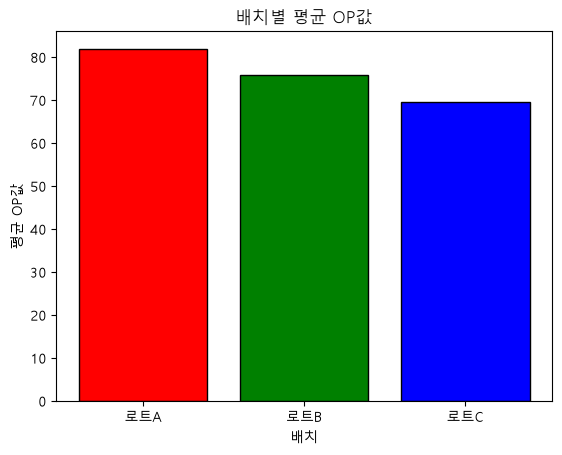

In [15]:
plt.bar(배치.index, 배치.values, color=['r','g','b'], edgecolor='black')
plt.xlabel("배치")
plt.ylabel("평균 OP값")
plt.title("배치별 평균 OP값")
plt.show()

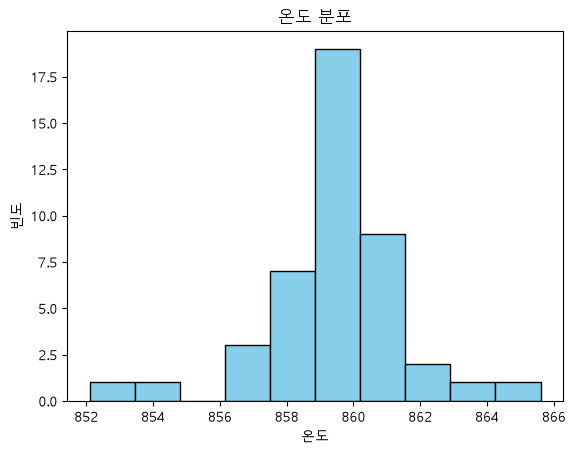

In [17]:
plt.hist(df['온도'], bins=10, color='skyblue', edgecolor='black')
plt.xlabel("온도")
plt.ylabel("빈도")
plt.title("온도 분포")
plt.show()

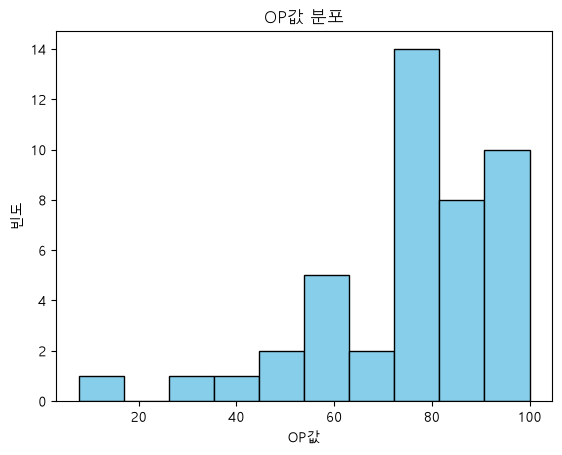

In [26]:
plt.hist(df['OP값'], bins=10, color='skyblue', edgecolor='black')
plt.xlabel("OP값")
plt.ylabel("빈도")
plt.title("OP값 분포")
plt.show()

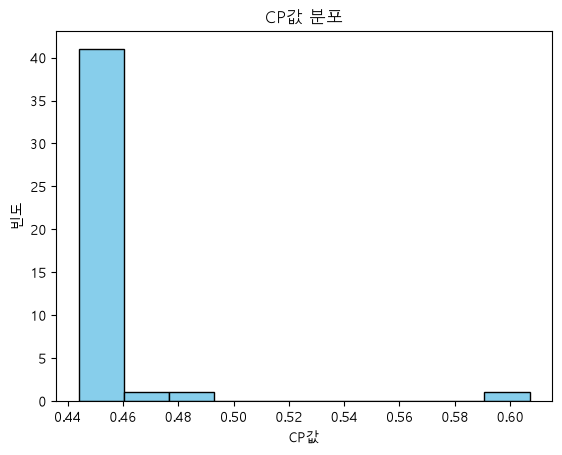

In [22]:
plt.hist(df['CP값'], bins=10, color='skyblue', edgecolor='black')
plt.xlabel("CP값")
plt.ylabel("빈도")
plt.title("CP값 분포")
plt.show()

In [18]:
df.columns

Index(['측정시각', '배치', '온도', 'OP값', 'CP값', '상태'], dtype='str')

In [30]:
df['온도'].mean(),df['온도'].std()

(np.float64(859.5318181818183), np.float64(2.105118096148406))

In [32]:
round(df['온도'].mean() + 1 * df['온도'].std(), 2)

np.float64(861.64)

In [33]:
df[df['온도'] >=862]

,측정시각,배치,온도,OP값,CP값,상태
25,10:40,로트B,862.9,28.5,0.449,정상
32,09:30,로트C,865.6,7.7,0.450,정상


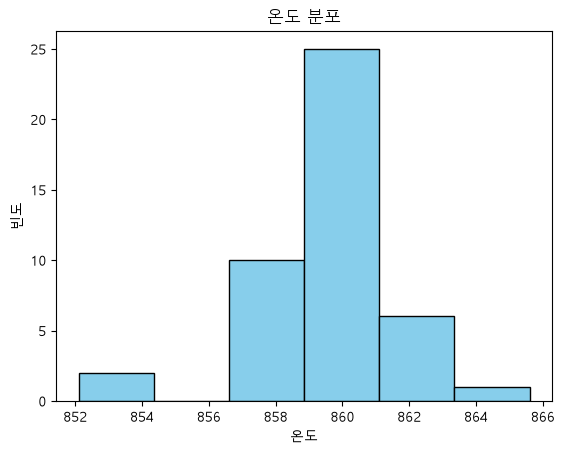

In [28]:
plt.hist(df['온도'], bins=6, color='skyblue', edgecolor='black')
plt.xlabel("온도")
plt.ylabel("빈도")
plt.title("온도 분포")
plt.show()

In [ ]:
#상관   
#df.corr()

In [34]:
df.columns

Index(['측정시각', '배치', '온도', 'OP값', 'CP값', '상태'], dtype='str')

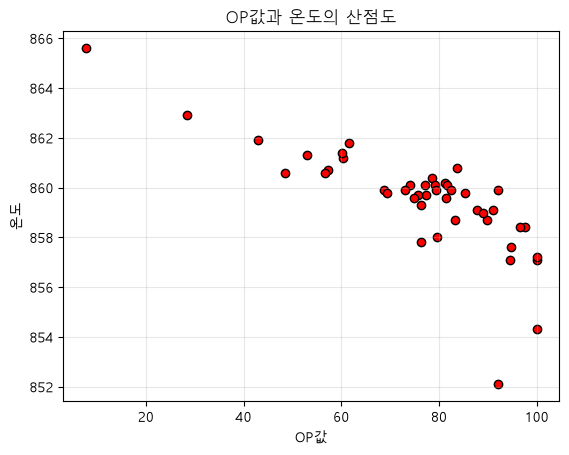

In [47]:
#'OP값''온도' 산점도
plt.scatter(df['OP값'], df['온도'], c='red', marker='o', edgecolor='black')
plt.xlabel("OP값")
plt.ylabel("온도")
plt.grid(True, alpha=0.3)
plt.title("OP값과 온도의 산점도")
plt.show()

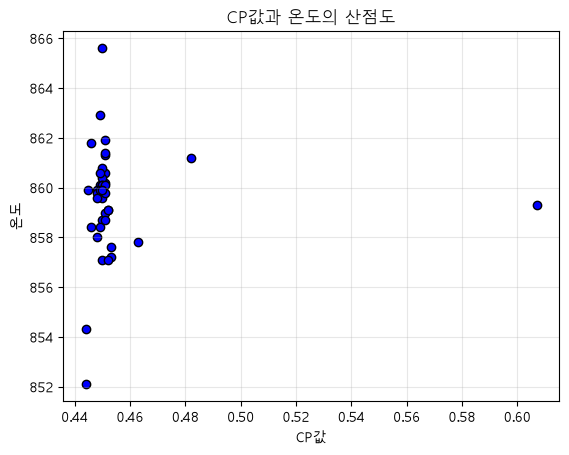

In [48]:
#'CP값''온도' 산점도
plt.scatter(df['CP값'], df['온도'], c='b', marker='o', edgecolor='black')
plt.xlabel("CP값")
plt.ylabel("온도")
plt.grid(True, alpha=0.3)
plt.title("CP값과 온도의 산점도")
plt.show()

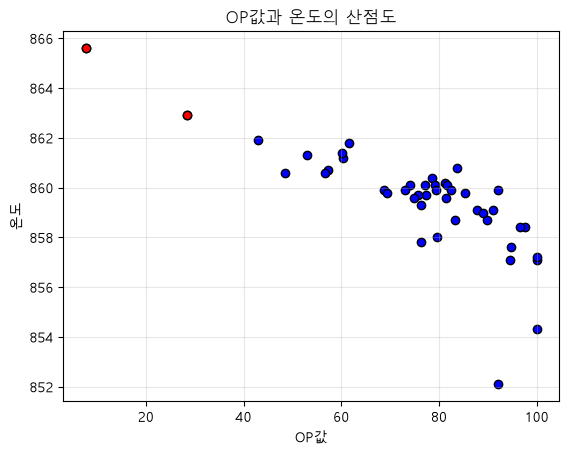

In [61]:
#'OP값''온도' 산점도
plt.scatter(df['OP값'], df['온도'], c='blue', marker='o', edgecolor='black')
plt.xlabel("OP값")
plt.ylabel("온도")

plt.scatter(df_sig['OP값'], df_sig['온도'], c='red', marker='o', edgecolor='black')


plt.grid(True, alpha=0.3)
plt.title("OP값과 온도의 산점도")
plt.show()

In [58]:
df_sig=df[df['온도'] >=862]

In [63]:
df_승온=df[df['상태'] == '승온']
df_승온.head()

,측정시각,배치,온도,OP값,CP값,상태
7,10:10,로트A,852.1,92.0,0.444,승온
12,11:00,로트A,854.3,100.0,0.444,승온


In [65]:
색=df['상태'].map({'정상': 'blue', '승온': 'red'})

In [ ]:
plt.axvline(y=90)

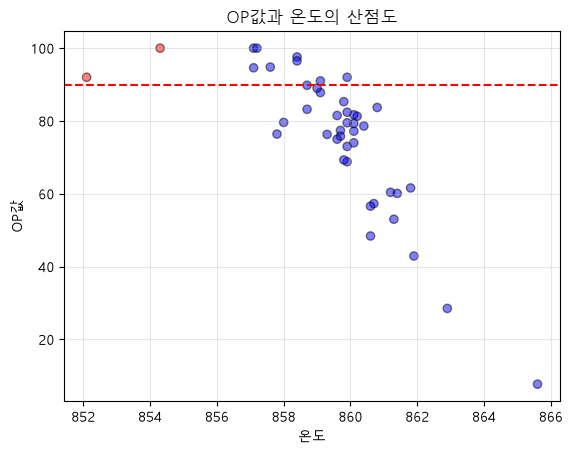

In [78]:
#'OP값''온도' 산점도
plt.scatter(df['온도'], df['OP값'], c=색, marker='o', edgecolor='black', alpha = 0.5)
plt.xlabel("온도")
plt.ylabel("OP값")
plt.grid(True, alpha=0.3)
plt.title("OP값과 온도의 산점도")
plt.axhline(y=90, color='red', linestyle='--')
plt.show()

In [ ]:
#온도 cp

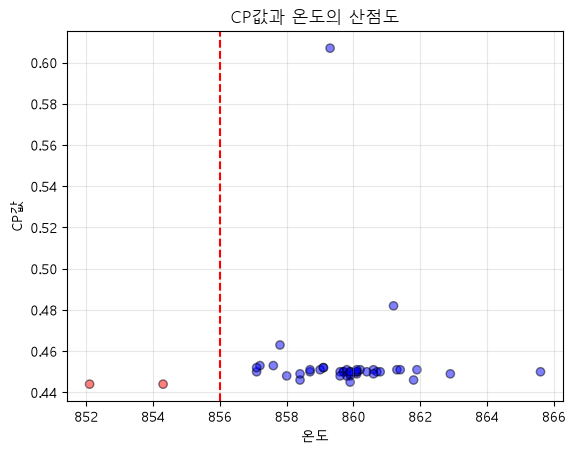

In [89]:
#'OP값''온도' 산점도
plt.scatter(df['온도'], df['CP값'], color=색, marker='o', edgecolor='black', alpha = 0.5)
plt.xlabel("온도")
plt.ylabel("CP값")
plt.axvline(x=856, color='red', linestyle='--')
plt.grid(True, alpha=0.3)
plt.title("CP값과 온도의 산점도")
plt.show()

In [94]:
df1 = pd.read_csv(heat_work)
df1.head()

,측정시각,소입로온도1존,소입로온도2존,CP값,OP값,세정기,라인,result
0,1,861.9,860.2,0.451,42.9,60.7,주간,정상
1,2,855.1,860.2,0.443,85.0,61.1,주간,정상
2,3,855.0,860.1,0.447,100.0,61.5,주간,정상
3,4,858.4,859.9,NaN,80.1,61.9,주간,정상
4,5,858.6,859.9,0.453,95.0,62.2,주간,정상


In [95]:
df1.isna().sum()

측정시각       0
소입로온도1존    0
소입로온도2존    8
CP값        6
OP값        6
세정기        5
라인         0
result     0
dtype: int64

In [97]:
#결측치 채우기
df2=df1.fillna(df1.mean(numeric_only=True))
df2.isna().sum()


측정시각       0
소입로온도1존    0
소입로온도2존    0
CP값        0
OP값        0
세정기        0
라인         0
result     0
dtype: int64

In [99]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   측정시각     120 non-null    int64  
 1   소입로온도1존  120 non-null    float64
 2   소입로온도2존  120 non-null    float64
 3   CP값      120 non-null    float64
 4   OP값      120 non-null    float64
 5   세정기      120 non-null    float64
 6   라인       120 non-null    str    
 7   result   120 non-null    str    
dtypes: float64(5), int64(1), str(2)
memory usage: 9.0 KB


In [100]:
np.sqrt(120)

np.float64(10.954451150103322)

In [104]:
line_value_couts=df2['라인'].value_counts()
line_value_couts

라인
주간    60
야간    60
Name: count, dtype: int64

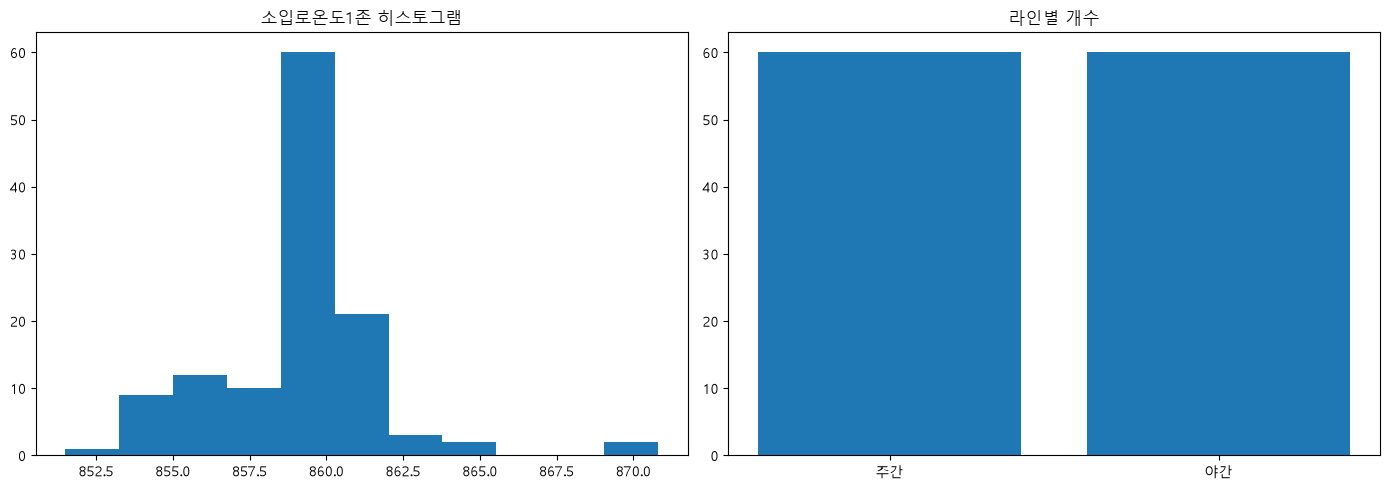

In [124]:
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.hist(df2['소입로온도1존'], bins=11) 
plt.title('소입로온도1존 히스토그램')

plt.subplot(1,2,2)
plt.bar(line_value_couts.index, line_value_couts.values)
plt.title('라인별 개수')





plt.tight_layout()
plt.show()


In [126]:
df2.columns

Index(['측정시각', '소입로온도1존', '소입로온도2존', 'CP값', 'OP값', '세정기', '라인', 'result'], dtype='str')

In [141]:
색=df2['result'].map({'정상': 'blue', '이상': 'red'})

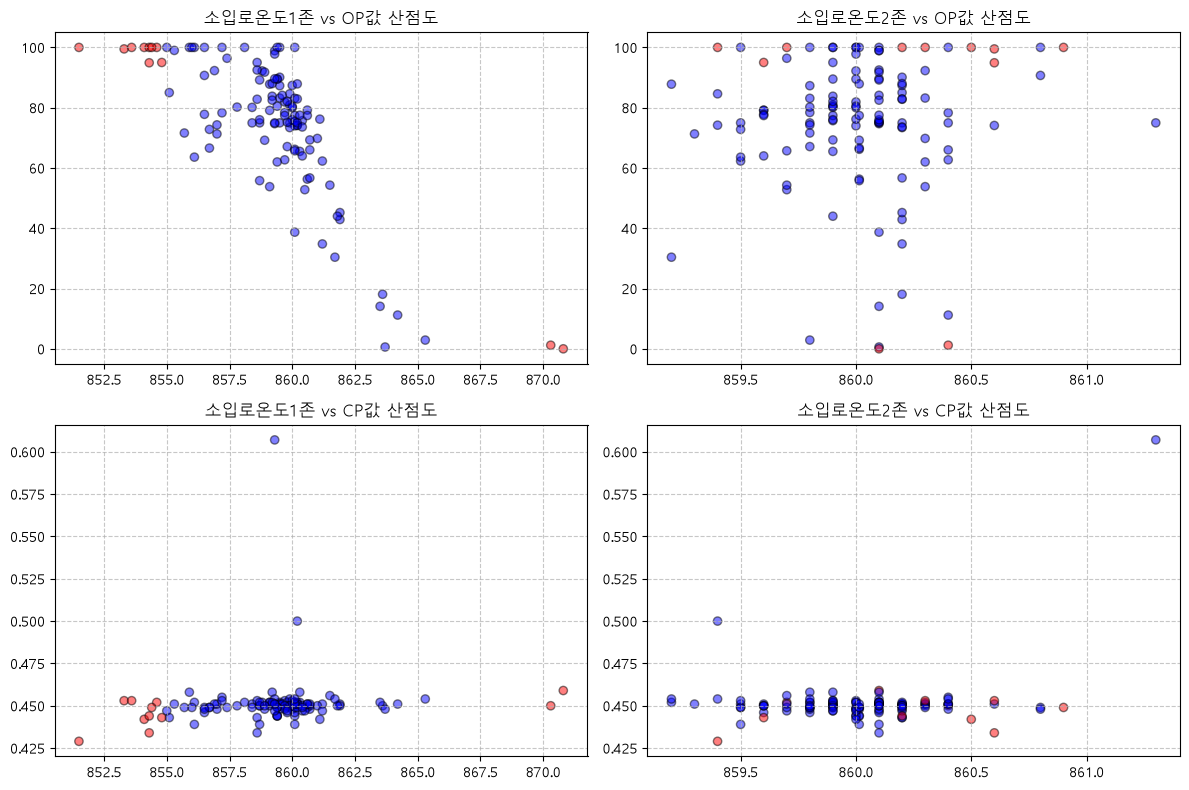

In [146]:
plt.figure(figsize=(12,8))

plt.subplot(2,2,1)
plt.scatter(df2['소입로온도1존'], df2['OP값'], color=색, marker='o', edgecolor='black', alpha = 0.5)
plt.title('소입로온도1존 vs OP값 산점도')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(2,2,2)
plt.scatter(df2['소입로온도2존'], df2['OP값'], color=색, marker='o', edgecolor='black', alpha = 0.5)
plt.title('소입로온도2존 vs OP값 산점도')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(2,2,3)
plt.scatter(df2['소입로온도1존'], df2['CP값'], color=색, marker='o', edgecolor='black', alpha = 0.5)
plt.title('소입로온도1존 vs CP값 산점도')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(2,2,4)
plt.scatter(df2['소입로온도2존'], df2['CP값'], color=색, marker='o', edgecolor='black', alpha = 0.5)
plt.title('소입로온도2존 vs CP값 산점도')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


In [147]:
#실습7

In [155]:
dfdf=pd.read_csv(heatt)

In [156]:
dfdf.head()

,라인,소입로온도,제어출력,건조출력,세정기,CP값,판정
0,주간,861.9,42.9,24.7,60.7,0.451,정상
1,주간,857.8,68.5,20.1,61.6,0.449,정상
2,주간,860.4,70.8,26.0,62.5,0.448,정상
3,주간,859.2,84.2,23.7,63.5,0.454,정상
4,주간,858.5,96.5,21.9,63.2,0.450,정상


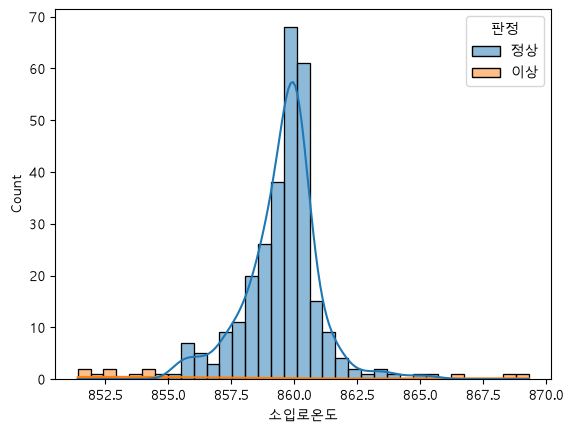

In [159]:
sns.histplot(dfdf, x='소입로온도', hue='판정', kde=True)
plt.show()


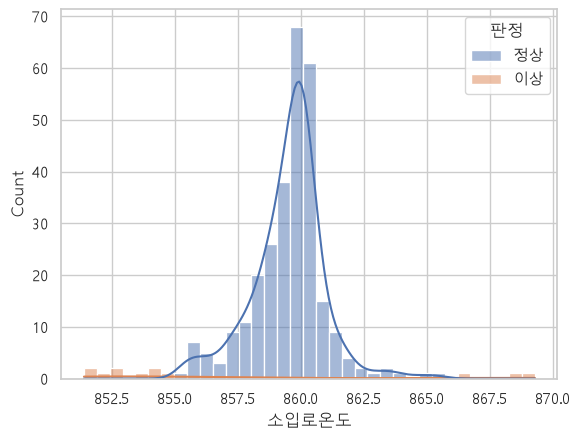

In [168]:
# seaborn 테마 먼저 설정
sns.set_theme(style='whitegrid')

# 한글 글꼴 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

sns.histplot(dfdf, x='소입로온도', hue='판정', kde=True)
plt.show()

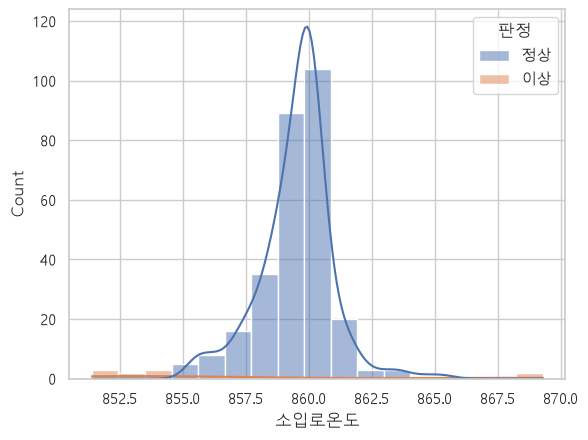

In [176]:
sns.set_theme(style='whitegrid', font = 'Malgun Gothic')

sns.histplot(dfdf, x='소입로온도', hue='판정',bins=17, kde=True)
plt.show()

<Figure size 1000x600 with 0 Axes>

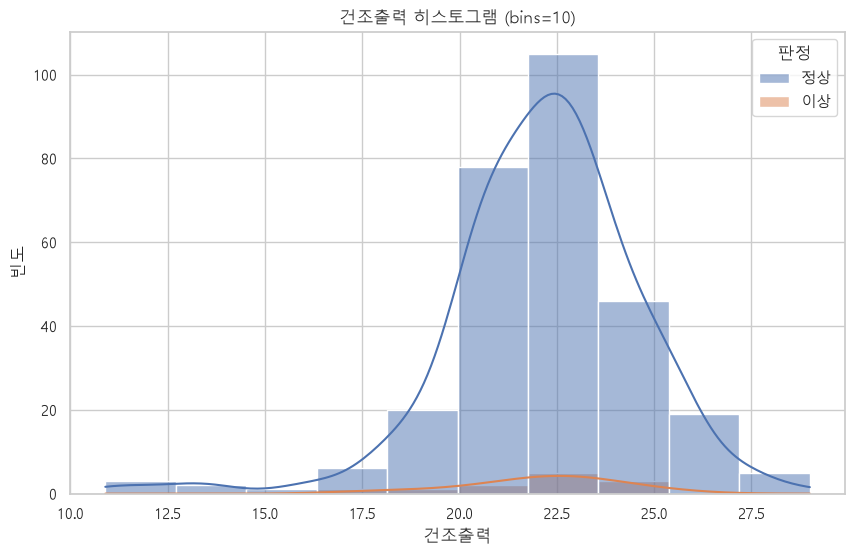

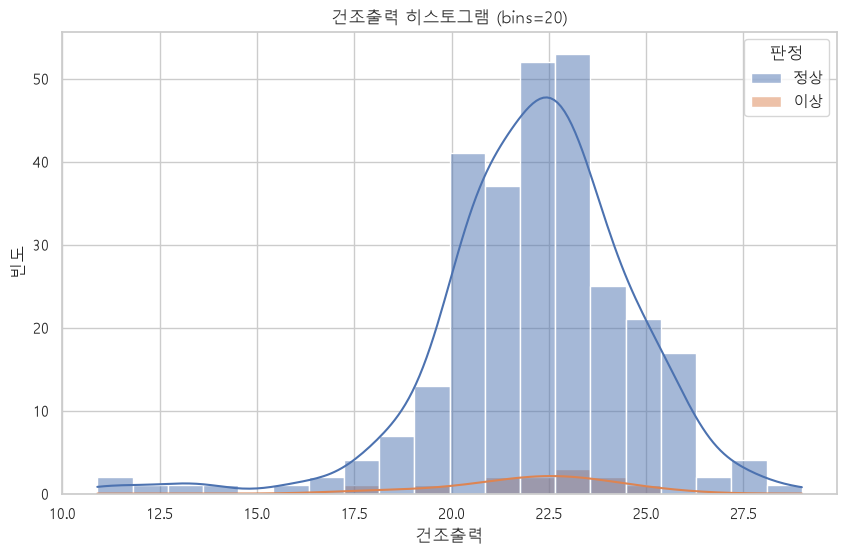

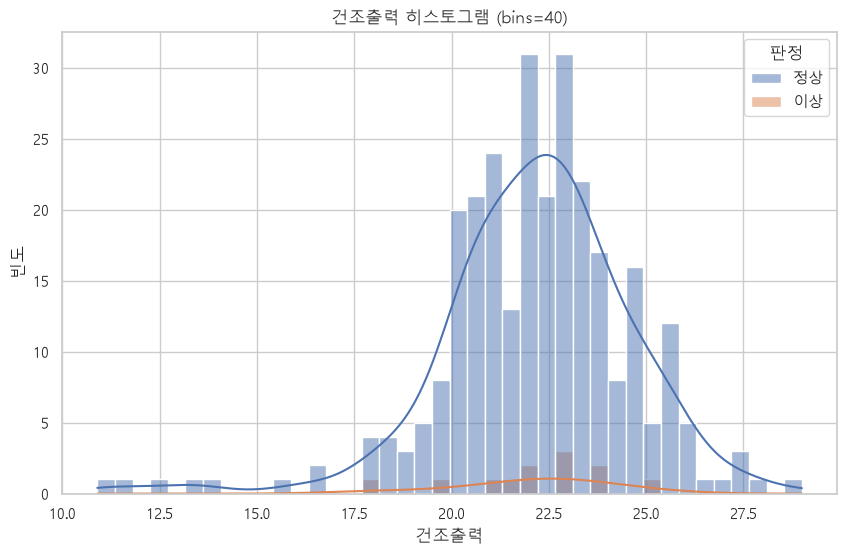

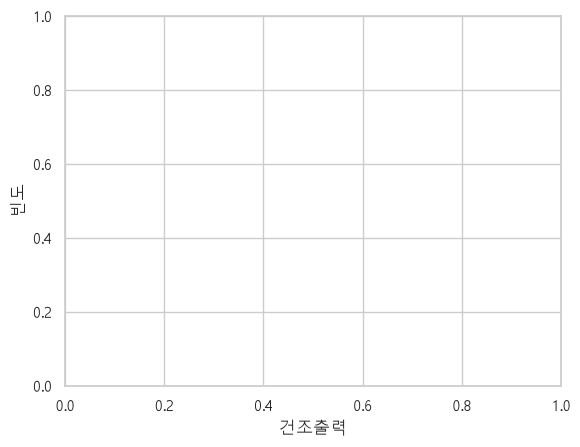

In [196]:
sns.set_theme(style='whitegrid', font = 'Malgun Gothic') #2

plt.figure(figsize=(10,6))


for bins in [10, 20, 40]:
    plt.figure(figsize=(10,6))
    sns.histplot(dfdf, x='건조출력', hue='판정', bins=bins, kde=True)
    plt.title(f'건조출력 히스토그램 (bins={bins})')
    plt.xlabel('건조출력')
    plt.ylabel('빈도')
    plt.show()

plt.xlabel('건조출력')
plt.ylabel('빈도')

plt.show()

<Figure size 1000x600 with 0 Axes>

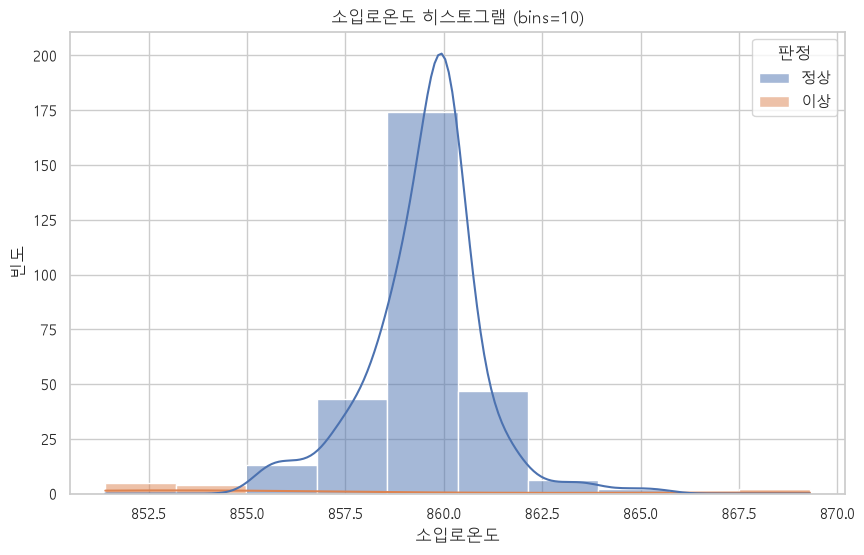

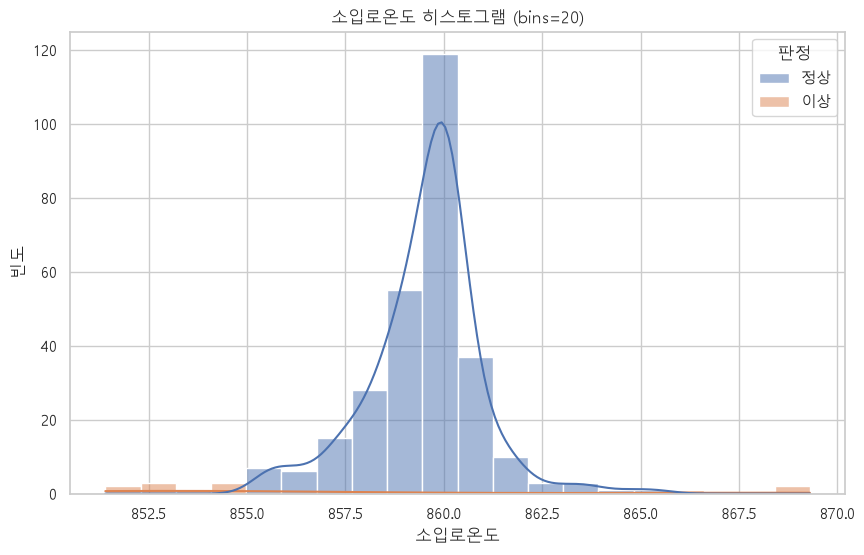

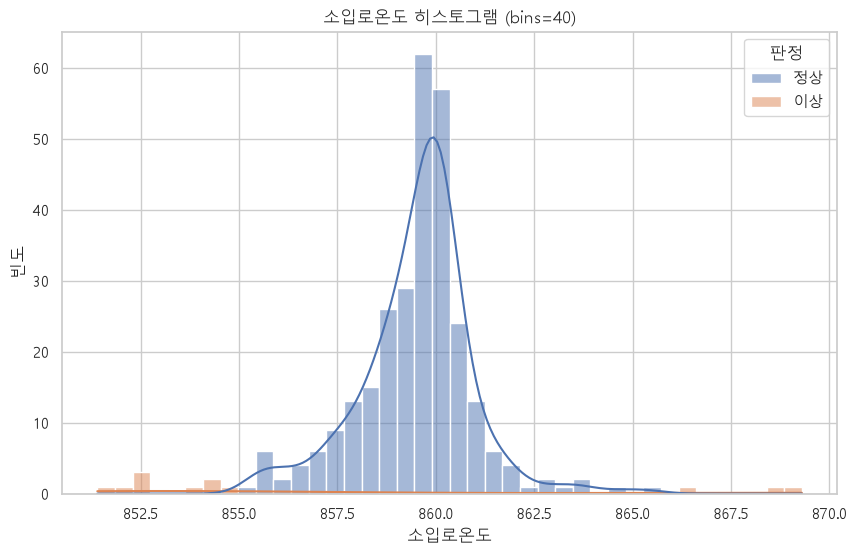

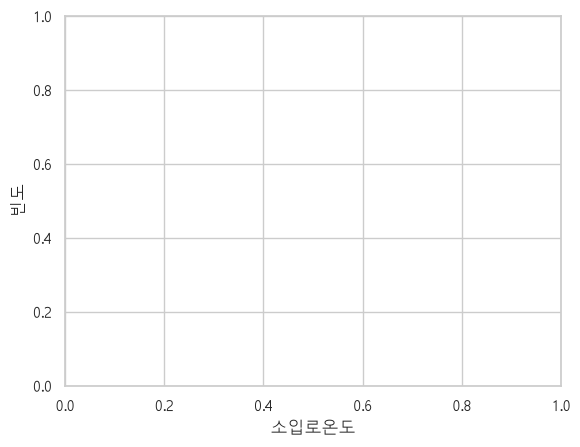

In [197]:
sns.set_theme(style='whitegrid', font = 'Malgun Gothic') #2

plt.figure(figsize=(10,6))


for bins in [10, 20, 40]:
    plt.figure(figsize=(10,6))
    sns.histplot(dfdf, x='소입로온도', hue='판정', bins=bins, kde=True)
    plt.title(f'소입로온도 히스토그램 (bins={bins})')
    plt.xlabel('소입로온도')
    plt.ylabel('빈도')
    plt.show()

plt.xlabel('소입로온도')
plt.ylabel('빈도')

plt.show()

In [201]:
dfdf.head()

,라인,소입로온도,제어출력,건조출력,세정기,CP값,판정
0,주간,861.9,42.9,24.7,60.7,0.451,정상
1,주간,857.8,68.5,20.1,61.6,0.449,정상
2,주간,860.4,70.8,26.0,62.5,0.448,정상
3,주간,859.2,84.2,23.7,63.5,0.454,정상
4,주간,858.5,96.5,21.9,63.2,0.450,정상


<Figure size 1000x600 with 0 Axes>

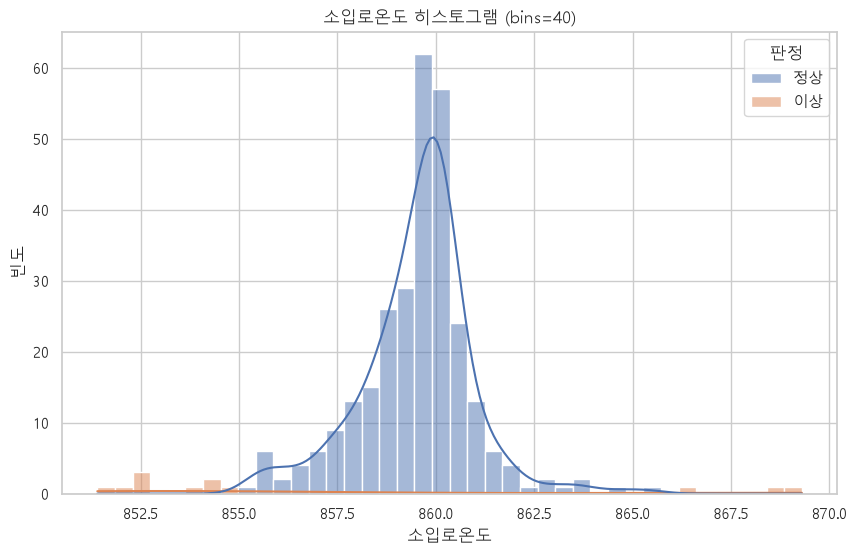

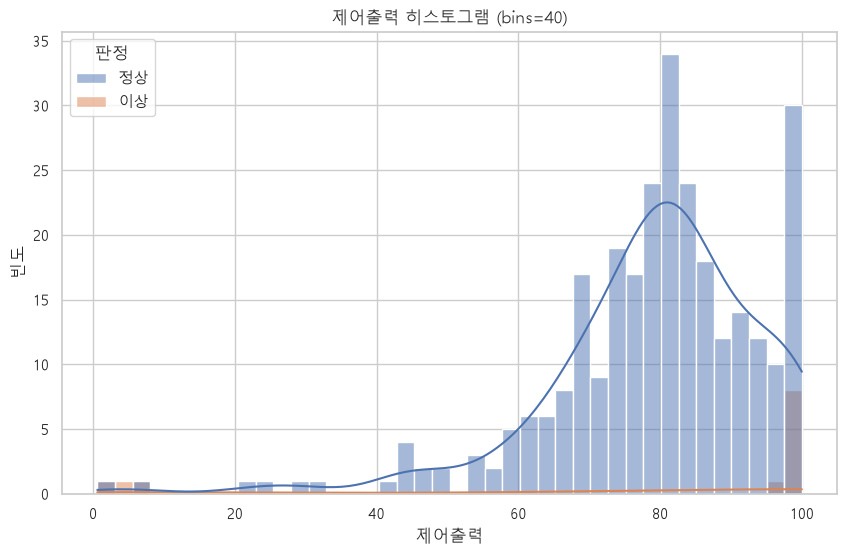

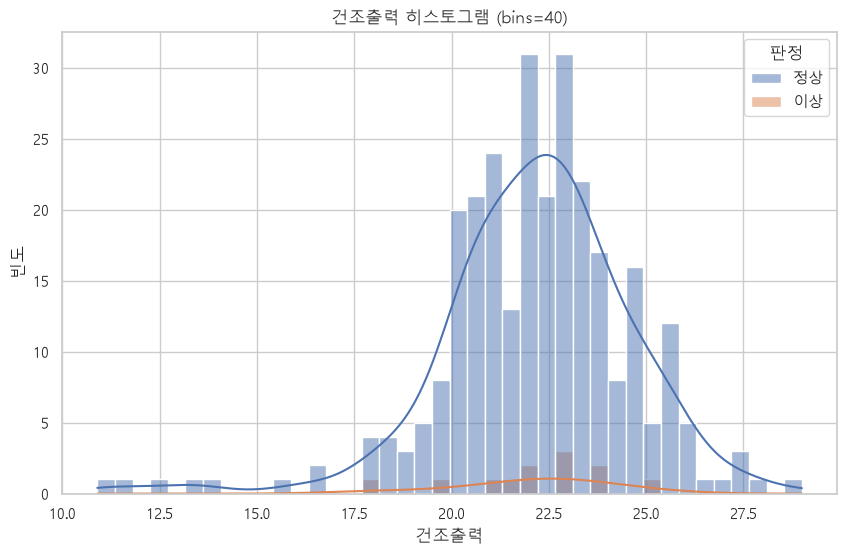

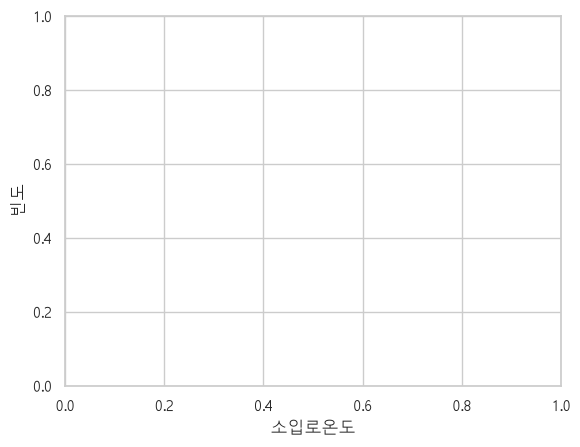

In [202]:
sns.set_theme(style='whitegrid', font = 'Malgun Gothic') #2

plt.figure(figsize=(10,6))


for x,y in [('소입로온도','°C'), ('제어출력','%'), ('건조출력','%')]:
    plt.figure(figsize=(10,6))
    sns.histplot(dfdf, x=x, hue='판정', bins=bins, kde=True)
    plt.title(f'{x} 히스토그램 (bins={bins})')
    plt.xlabel(x)
    plt.ylabel('빈도')
    plt.show()

plt.xlabel('소입로온도')
plt.ylabel('빈도')

plt.show()

[('소입로온도','°C'), ('제어출력','%'), ('건조출력 ','%')]

In [203]:
dfdf.columns

Index(['라인', '소입로온도', '제어출력', '건조출력', '세정기', 'CP값', '판정'], dtype='str')

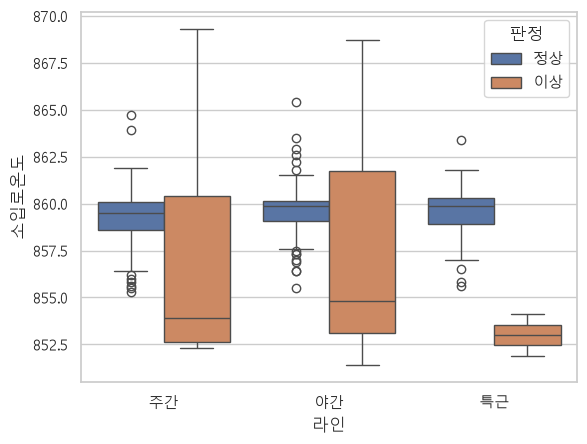

In [207]:
sns.boxplot(dfdf, x='라인', y='소입로온도', hue='판정')
plt.show()

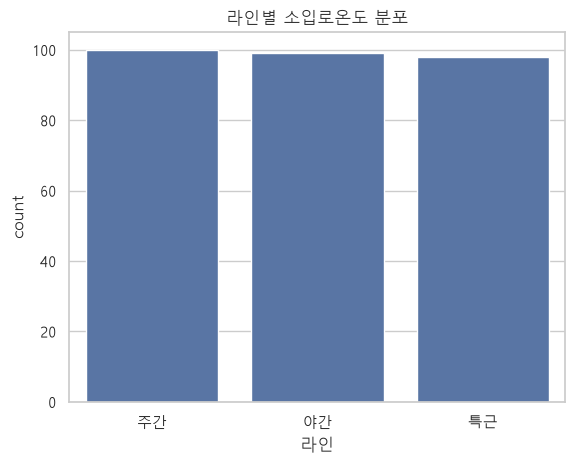

In [213]:
sns.countplot(data=dfdf, x='라인')
plt.title('라인별 소입로온도 분포')
plt.show()

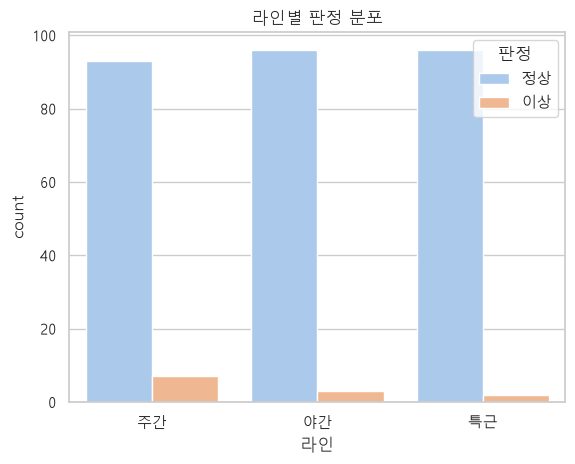

In [220]:
sns.countplot(data=dfdf, x='라인', hue='판정', palette='pastel',)
plt.title('라인별 판정 분포')
plt.show()

In [235]:
표=dfdf.groupby(['라인', '판정'], observed=True).size().unstack(fill_value=0)
표

판정,이상,정상
라인,,
야간,3,96
주간,7,93
특근,2,96


In [ ]:
sns.algorithms